# Claim Archetypes: Clustering Flood Claims by What Happened

**DSC 411/511 Semester Project** · Venkat Repaka, Ritik Gaire

In notebooks 04 and 05 we clustered claims on **building facts** (foundation, occupancy, floors). Those groups mostly repeated the
foundation code. Here we cluster on **what happened in the flood**: how badly the building was damaged, how deep the water was,
and how big and old the building is. We call the groups **claim archetypes**.

| Step | What we do |
|---|---|
| 1 | Build the claim features from the raw file (same claims as notebook 03, duplicates removed) |
| 2 | Cluster with **K-means**, a **Gaussian mixture (GMM)** and **HDBSCAN**, and check how much they agree |
| 3 | Profile each archetype by **flood zone**, **event** and **state** |
| 4 | Check whether the mix of archetypes **shifts in 2021 (Ida) and 2022 (Ian) compared with 2020** |

**Related work.** *FloodGenome* (arXiv 2403.10625) computes each building's **damage ratio** (damage ÷ building property value)
from NFIP claims, averages it per census block group, and clusters the block groups with K-means. We use the same damage ratio,
but we cluster **individual claims**, because the redacted claims file has no block-group building counts.

These clusters **describe** claims after the flood. They use damage, so they are **not** a prediction model (unlike RQ1 and RQ2).

---
# Section 1: Data and claim features

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, HDBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.stats import chi2_contingency
import warnings; warnings.filterwarnings('ignore')
SEED = 42
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)

RAW = '/Users/home/workspace/School/DataMining/project/NfipClaimsV3.parquet'
cols = ['id', 'yearOfLoss', 'dateOfLoss', 'state', 'ratedFloodZone', 'floodEvent', 'waterDepth', 'floodWaterDuration',
        'buildingDamageAmount', 'buildingPropertyValue', 'buildingReplacementCost', 'totalBuildingInsuranceCoverage',
        'originalConstructionDate']
raw = pd.read_parquet(RAW, columns=cols)
raw = raw[raw['yearOfLoss'].between(2020, 2025)]
keep_ids = pd.read_parquet('outputs/nfip_claims_simple_keys.parquet', columns=['id'])['id']
df = raw[raw['id'].isin(keep_ids)].copy()                      # same claims as notebook 03 (duplicates removed)
for c in ['waterDepth', 'floodWaterDuration', 'buildingDamageAmount', 'buildingPropertyValue',
          'buildingReplacementCost', 'totalBuildingInsuranceCoverage']:
    df[c] = df[c].astype(float)
df['year'] = df['yearOfLoss'].astype(int)
built = pd.to_datetime(df['originalConstructionDate'].astype(str), errors='coerce', format='%Y-%m-%d')
df['construction_year'] = built.dt.year.where(built.dt.year.between(1800, 2025))
df['event'] = df['floodEvent'].fillna('no named event')
z = df['ratedFloodZone'].astype(str).str.upper()
df['zone'] = np.select([z.isin(['X', 'B', 'C']), z.str.startswith('V'), z.str.startswith('A')], ['X (outside)', 'V (coastal)', 'A (inside)'], 'other')
print(f'Claims 2020-2025 (duplicates removed): {len(df):,}')

Claims 2020-2025 (duplicates removed): 276,570


## 1.1 Which features can we use?

We wanted six features: damage ratio, water depth, flood duration, replacement cost, coverage and construction year.
First we check how complete each one is **in each year**, because Section 4 compares years.

In [2]:
check = pd.DataFrame({
    'damage': df['buildingDamageAmount'].notna(),
    'property value > 0': df['buildingPropertyValue'] > 0,
    'water depth (not 99)': df['waterDepth'].notna() & (df['waterDepth'] != 99),
    'flood duration': df['floodWaterDuration'].notna(),
    'replacement cost > 0': df['buildingReplacementCost'] > 0,
    'coverage > 0': df['totalBuildingInsuranceCoverage'] > 0,
    'construction year': df['construction_year'].notna()})
avail = check.groupby(df['year']).mean().T
avail['all years'] = check.mean()
(avail * 100).round(1)

year,2020,2021,2022,2023,2024,2025,all years
damage,86.8,90.5,86.8,87.3,90.6,90.2,89.0
property value > 0,80.9,80.0,73.1,78.8,80.9,83.3,79.0
water depth (not 99),77.8,79.4,82.7,73.0,83.2,72.3,80.5
flood duration,0.1,0.4,2.0,5.8,9.0,28.1,5.6
replacement cost > 0,80.9,80.1,73.7,78.6,81.0,83.4,79.2
coverage > 0,98.3,98.3,96.7,98.0,97.5,98.7,97.7
construction year,99.3,99.9,99.8,99.5,98.5,98.1,99.2


**Flood duration cannot be used.** It is filled for only about 6% of claims, and almost never before 2023
(see the table). Clustering on it would drop 2020-2022, exactly the years we want to compare. We use it only as a profile
column where it exists. The other five features are filled for most claims.

## 1.2 Build the five features

| Feature | How | Why this form |
|---|---|---|
| **damage ratio** | building damage ÷ building property value (as in FloodGenome) | compares damage across cheap and expensive buildings |
| **water depth** | `waterDepth` as recorded | 99 is FEMA's "unknown" code → removed; negative values have no clear meaning → removed |
| **replacement cost** | log10 of building replacement cost | very skewed (a few condo towers) |
| **coverage** | log10 of building coverage | very skewed |
| **construction year** | year from the original construction date | |

Noise rules: a damage ratio above 1 (damage larger than the building's value) is impossible, so those claims are removed.
We keep claims with **some building damage** (damage > 0), because an archetype of "no damage" is not a flood outcome.

In [3]:
df['damage_ratio'] = df['buildingDamageAmount'] / df['buildingPropertyValue'].where(df['buildingPropertyValue'] > 0)
df['water_depth'] = df['waterDepth'].where(df['waterDepth'].between(0, 98))
df['log_replacement_cost'] = np.log10(df['buildingReplacementCost'].where(df['buildingReplacementCost'] > 0))
df['log_coverage'] = np.log10(df['totalBuildingInsuranceCoverage'].where(df['totalBuildingInsuranceCoverage'] > 0))
FEATURES = ['damage_ratio', 'water_depth', 'log_replacement_cost', 'log_coverage', 'construction_year']

steps = [('all claims', pd.Series(True, index=df.index)),
         ('damage > 0', df['buildingDamageAmount'] > 0),
         ('damage ratio known and <= 1', df['damage_ratio'].le(1)),
         ('water depth known (0-98)', df['water_depth'].notna()),
         ('replacement cost, coverage, construction year known', df[['log_replacement_cost', 'log_coverage', 'construction_year']].notna().all(axis=1))]
mask = pd.Series(True, index=df.index)
for name, m in steps:
    mask &= m
    print(f'{name:55s} {mask.sum():>8,}')
C = df[mask].copy()
print(f'\nClaims used for clustering: {len(C):,} ({len(C) / len(df):.0%})')
print('Claims per year:', C['year'].value_counts().sort_index().to_dict())
C[FEATURES].describe().round(2)

all claims                                               276,570
damage > 0                                               221,236
damage ratio known and <= 1                              208,112
water depth known (0-98)                                 163,572
replacement cost, coverage, construction year known      162,066

Claims used for clustering: 162,066 (59%)
Claims per year: {2020: 17795, 2021: 25319, 2022: 34226, 2023: 11919, 2024: 65319, 2025: 7488}


,damage_ratio,water_depth,log_replacement_cost,log_coverage,construction_year
count,162066.00,162066.00,162066.00,162066.00,162066.00
mean,0.29,1.77,5.53,5.34,1973.72
std,0.25,4.28,0.39,0.33,21.13
min,0.00,0.00,1.49,3.00,1800.00
25%,0.06,0.00,5.31,5.28,1961.00
50%,0.24,1.00,5.47,5.40,1973.00
75%,0.47,2.00,5.67,5.40,1986.00
max,1.00,97.00,9.22,8.44,2025.00


---
# Section 2: Clustering

All five features are standardized (mean 0, standard deviation 1), so no feature dominates the distance.

## 2.1 K-means: choose k
Rule (fixed before looking): the **k between 3 and 8 with the highest silhouette** on a 10,000-claim sample.
Fewer than 3 groups would be too rough to be called archetypes.

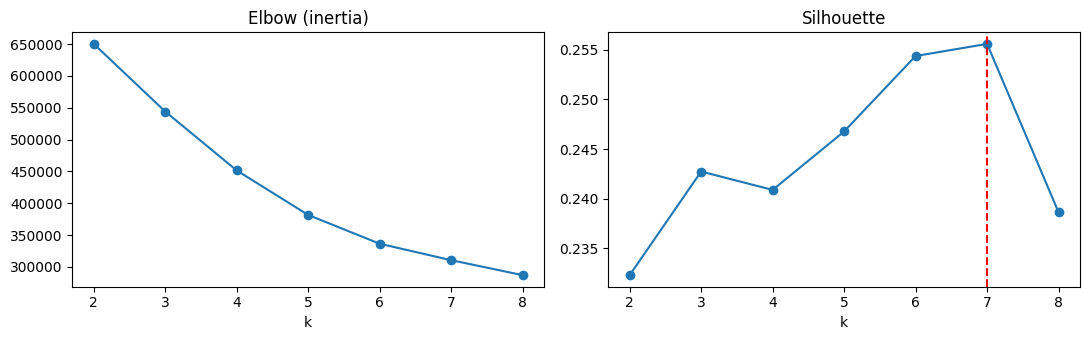

 k    inertia  silhouette
 2 650352.893       0.232
 3 543989.301       0.243
 4 451433.728       0.241
 5 381501.412       0.247
 6 336295.134       0.254
 7 310461.350       0.256
 8 286927.213       0.239
Chosen k: 7


In [4]:
X = StandardScaler().fit_transform(C[FEATURES])
rng = np.random.default_rng(SEED)
sample = rng.choice(len(X), 10_000, replace=False)
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    rows.append({'k': k, 'inertia': km.inertia_, 'silhouette': silhouette_score(X[sample], km.labels_[sample])})
ksel = pd.DataFrame(rows)
K = int(ksel[ksel['k'] >= 3].sort_values('silhouette', ascending=False)['k'].iloc[0])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(ksel['k'], ksel['inertia'], marker='o'); ax[0].set_title('Elbow (inertia)'); ax[0].set_xlabel('k')
ax[1].plot(ksel['k'], ksel['silhouette'], marker='o'); ax[1].axvline(K, color='red', ls='--'); ax[1].set_title('Silhouette'); ax[1].set_xlabel('k')
plt.tight_layout(); plt.show()
print(ksel.round(3).to_string(index=False)); print('Chosen k:', K)
km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X)
C['kmeans'] = km.labels_

## 2.2 Gaussian mixture (GMM)
A GMM lets groups be **oval and of different sizes**, and gives each claim a probability of belonging to each group.
We choose the number of groups by **BIC** (lower is better), from 2 to 8.

In [5]:
bics = []
for k in range(2, 9):
    g = GaussianMixture(n_components=k, covariance_type='full', random_state=SEED).fit(X)
    bics.append({'k': k, 'BIC': g.bic(X)})
bics = pd.DataFrame(bics); KG = int(bics.loc[bics['BIC'].idxmin(), 'k'])
print(bics.round(0).to_string(index=False)); print('Best k by BIC:', KG)
gmm = GaussianMixture(n_components=KG, covariance_type='full', random_state=SEED).fit(X)
C['gmm'] = gmm.predict(X)
gmm_same_k = GaussianMixture(n_components=K, covariance_type='full', random_state=SEED).fit(X)
C['gmm_same_k'] = gmm_same_k.predict(X)
conf = gmm.predict_proba(X).max(axis=1)
print(f'Claims assigned with probability > 0.9: {(conf > 0.9).mean():.0%}')

 k       BIC
 2 1765237.0
 3  868447.0
 4  830264.0
 5  746919.0
 6  750624.0
 7  681195.0
 8  739255.0
Best k by BIC: 7


Claims assigned with probability > 0.9: 68%


## 2.3 HDBSCAN
HDBSCAN finds **dense regions** and calls claims outside them **noise** (label -1). It does not need k.
It is slow on many rows, so we run it on a 20,000-claim sample. Smallest group: 1% of the sample (200 claims).

In [6]:
hs = rng.choice(len(X), 20_000, replace=False)
hdb = HDBSCAN(min_cluster_size=200, min_samples=20).fit(X[hs])
lab = pd.Series(hdb.labels_)
print('HDBSCAN groups:', lab[lab >= 0].nunique(), '  noise claims:', f'{(lab == -1).mean():.0%}')
print(lab.value_counts().sort_index().to_dict())

HDBSCAN groups: 2   noise claims: 31%
{-1: 6290, 0: 13445, 1: 265}


## 2.4 Do the three methods agree?

In [7]:
s = sample
agree = pd.DataFrame([
    {'method': f'K-means (k={K})', 'groups': K, 'silhouette (10k sample)': silhouette_score(X[s], C['kmeans'].values[s]), 'ARI with K-means': 1.0},
    {'method': f'GMM (k={KG}, best BIC)', 'groups': KG, 'silhouette (10k sample)': silhouette_score(X[s], C['gmm'].values[s]),
     'ARI with K-means': adjusted_rand_score(C['kmeans'], C['gmm'])},
    {'method': f'GMM (k={K}, same as K-means)', 'groups': K, 'silhouette (10k sample)': silhouette_score(X[s], C['gmm_same_k'].values[s]),
     'ARI with K-means': adjusted_rand_score(C['kmeans'], C['gmm_same_k'])}])
in_cluster = lab.values >= 0
agree.loc[len(agree)] = {'method': 'HDBSCAN (20k sample, noise left out)', 'groups': lab[lab >= 0].nunique(),
                         'silhouette (10k sample)': silhouette_score(X[hs][in_cluster], lab.values[in_cluster]) if in_cluster.sum() > 1 and lab[lab >= 0].nunique() > 1 else np.nan,
                         'ARI with K-means': adjusted_rand_score(C['kmeans'].values[hs][in_cluster], lab.values[in_cluster])}
agree.round(3)

,method,groups,silhouette (10k sample),ARI with K-means
0,K-means (k=7),7,0.256,1.000
1,"GMM (k=7, best BIC)",7,0.016,0.181
2,"GMM (k=7, same as K-means)",7,0.016,0.181
3,"HDBSCAN (20k sample, noise left out)",2,0.194,0.028


---
# Section 3: Profiles of the K-means archetypes

We profile the K-means groups, because K-means uses every claim and has a fixed rule for k.
**Payment, flood zone, event and state were not used to form the groups.** They are only used to describe them.

In [8]:
prof = C.groupby('kmeans').agg(claims=('id', 'size'),
                               damage_ratio=('damage_ratio', 'median'),
                               water_depth=('water_depth', 'median'),
                               replacement_cost=('log_replacement_cost', lambda v: 10 ** v.median()),
                               coverage=('log_coverage', lambda v: 10 ** v.median()),
                               construction_year=('construction_year', 'median'),
                               median_damage=('buildingDamageAmount', 'median'),
                               duration_filled=('floodWaterDuration', lambda v: v.notna().mean()),
                               duration_median=('floodWaterDuration', 'median'))
prof['share'] = prof['claims'] / prof['claims'].sum()
prof = prof.sort_values('damage_ratio')
ORDER = list(prof.index)
prof.style.format({'damage_ratio': '{:.2f}', 'water_depth': '{:.0f}', 'replacement_cost': '${:,.0f}', 'coverage': '${:,.0f}',
                   'construction_year': '{:.0f}', 'median_damage': '${:,.0f}', 'duration_filled': '{:.0%}',
                   'duration_median': '{:.1f}', 'share': '{:.0%}'})

,claims,damage_ratio,water_depth,replacement_cost,coverage,construction_year,median_damage,duration_filled,duration_median,share
kmeans,,,,,,,,,,
0,2928,0.03,1,"$5,932,730","$5,000,000",1981,"$146,481",2%,0.0,2%
3,44082,0.07,1,"$312,170","$250,000",1991,"$15,466",6%,0.0,27%
6,15188,0.08,1,"$1,372,019","$500,000",1980,"$99,344",4%,0.0,9%
5,34796,0.13,1,"$285,864","$250,000",1956,"$27,972",8%,0.0,21%
2,13643,0.26,1,"$141,074","$55,000",1973,"$24,558",8%,0.0,8%
4,1257,0.43,38,"$301,433","$250,000",1966,"$107,062",97%,1.0,1%
1,50172,0.54,1,"$258,774","$250,000",1970,"$109,855",7%,0.0,31%


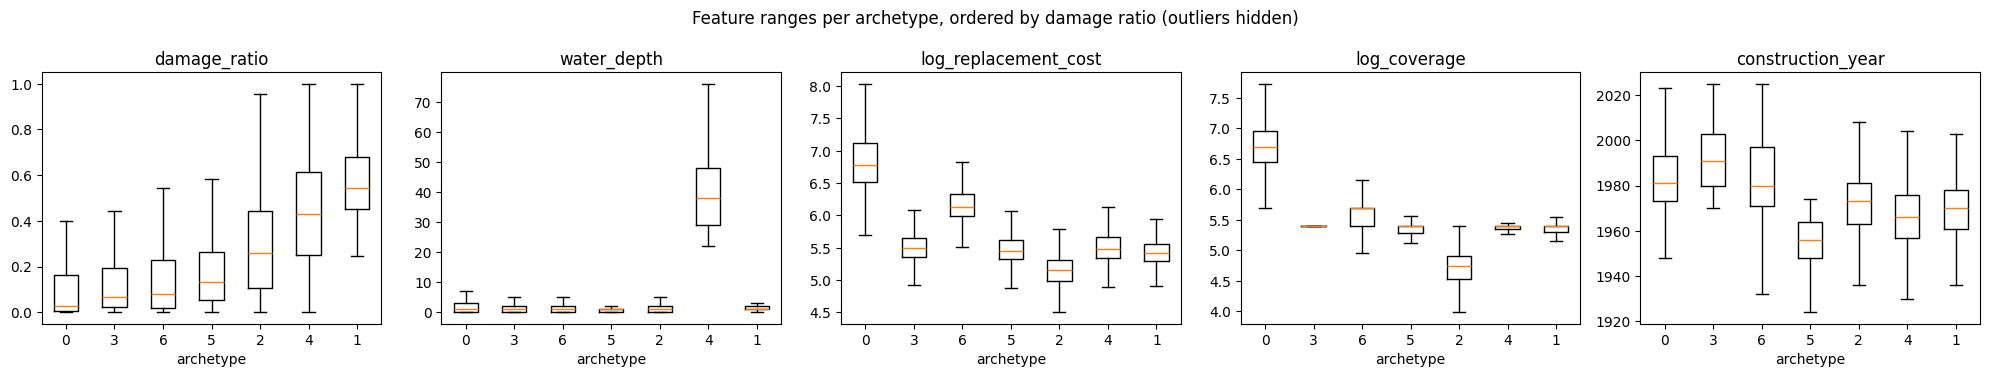

In [9]:
fig, axes = plt.subplots(1, len(FEATURES), figsize=(20, 3.8))
for a, f in zip(axes, FEATURES):
    a.boxplot([C.loc[C['kmeans'] == k, f] for k in ORDER], showfliers=False)
    a.set_xticks(range(1, K + 1), ORDER); a.set_title(f); a.set_xlabel('archetype')
plt.suptitle('Feature ranges per archetype, ordered by damage ratio (outliers hidden)'); plt.tight_layout(); plt.show()

## 3.1 Flood zone, event and state of each archetype

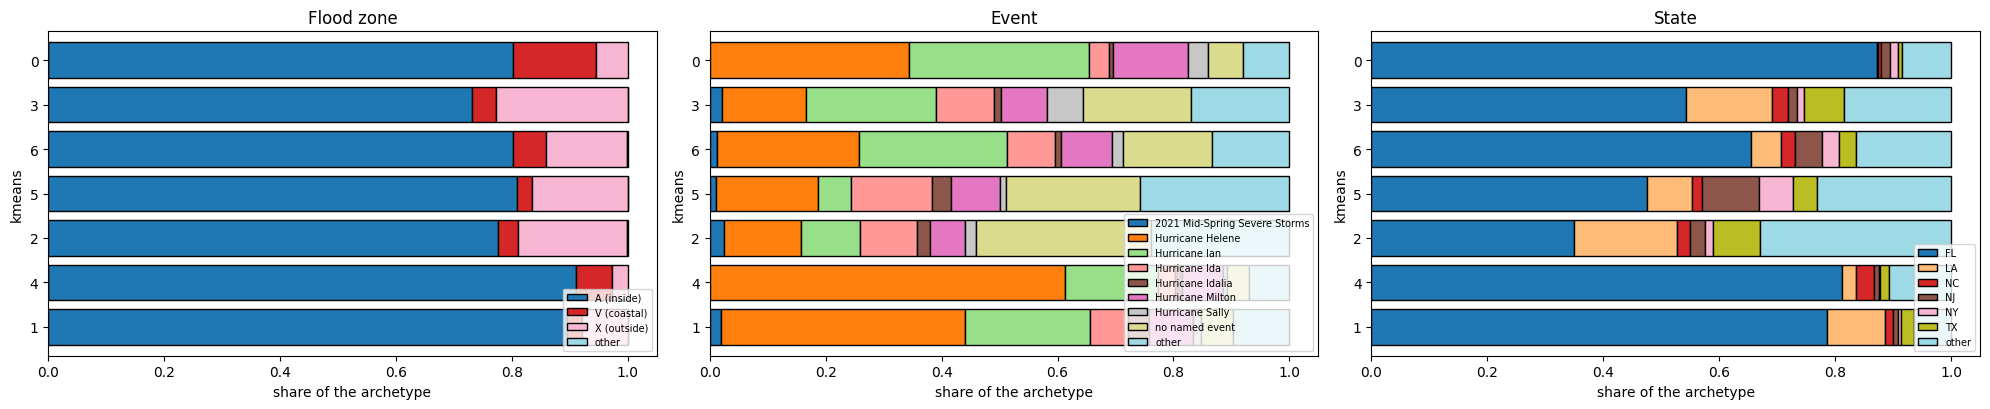

zone,A (inside),V (coastal),X (outside),other
kmeans,,,,
0,80.0,14.0,5.0,0.0
3,73.0,4.0,23.0,0.0
6,80.0,6.0,14.0,0.0
5,81.0,2.0,17.0,0.0
2,78.0,4.0,19.0,0.0
4,91.0,6.0,3.0,0.0
1,90.0,3.0,8.0,0.0


In [10]:
zone = pd.crosstab(C['kmeans'], C['zone'], normalize='index').loc[ORDER]
top_events = C['event'].value_counts().head(8).index
ev = pd.crosstab(C['kmeans'], C['event'].where(C['event'].isin(top_events), 'other'), normalize='index').loc[ORDER]
top_states = C['state'].value_counts().head(6).index
st = pd.crosstab(C['kmeans'], C['state'].where(C['state'].isin(top_states), 'other'), normalize='index').loc[ORDER]
fig, axes = plt.subplots(1, 3, figsize=(20, 4.2))
for a, t, title in [(axes[0], zone, 'Flood zone'), (axes[1], ev, 'Event'), (axes[2], st, 'State')]:
    t.plot.barh(stacked=True, ax=a, edgecolor='black', width=0.8, colormap='tab20')
    a.set_title(title); a.set_xlabel('share of the archetype'); a.legend(fontsize=7, loc='lower right'); a.invert_yaxis()
plt.tight_layout(); plt.show()
(zone * 100).round(0)

In [11]:
(ev * 100).round(0)

event,2021 Mid-Spring Severe Storms,Hurricane Helene,Hurricane Ian,Hurricane Ida,Hurricane Idalia,Hurricane Milton,Hurricane Sally,no named event,other
kmeans,,,,,,,,,
0,0.0,34.0,31.0,3.0,1.0,13.0,4.0,6.0,8.0
3,2.0,14.0,22.0,10.0,1.0,8.0,6.0,19.0,17.0
6,1.0,25.0,25.0,8.0,1.0,9.0,2.0,15.0,13.0
5,1.0,18.0,6.0,14.0,3.0,8.0,1.0,23.0,26.0
2,2.0,13.0,10.0,10.0,2.0,6.0,2.0,30.0,24.0
4,0.0,61.0,16.0,3.0,1.0,7.0,1.0,4.0,7.0
1,2.0,42.0,21.0,7.0,4.0,8.0,1.0,5.0,10.0


In [12]:
(st * 100).round(0)

state,FL,LA,NC,NJ,NY,TX,other
kmeans,,,,,,,
0,87.0,0.0,1.0,1.0,1.0,1.0,9.0
3,54.0,15.0,3.0,1.0,1.0,7.0,18.0
6,65.0,5.0,3.0,5.0,3.0,3.0,16.0
5,47.0,8.0,2.0,10.0,6.0,4.0,23.0
2,35.0,18.0,2.0,2.0,2.0,8.0,33.0
4,81.0,2.0,3.0,1.0,0.0,2.0,11.0
1,79.0,10.0,1.0,1.0,1.0,2.0,6.0


---
# Section 4: Does the mix of archetypes shift in 2021 (Ida) and 2022 (Ian) compared with 2020?

We compare the share of each archetype among claims of each loss year.
A **chi-square test** checks whether the mix differs more than chance would allow, and **Cramér's V** says how big the difference is
(0 = no difference, 0.1 = small, 0.3 = medium, 0.5 = large).

Share of each archetype by loss year (%):
kmeans    0     3     6     5     2    4     1
year                                          
2020    1.1  40.9   6.9  23.3  14.6  0.1  13.2
2021    0.6  30.8   7.9  28.5  11.8  0.2  20.2
2022    2.8  33.0  12.8  11.2   6.4  0.6  33.1
2023    0.8  17.0   7.7  40.7   7.1  0.3  26.4
2024    2.3  20.5   9.2  19.5   5.9  1.4  41.1
2025    0.5  30.4   8.0  26.5  15.8  0.6  18.1


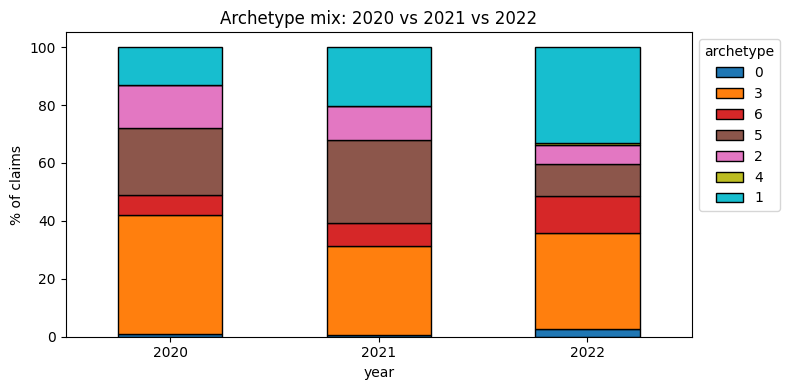

In [13]:
def compare(a, b, label_a, label_b):
    t = pd.DataFrame({label_a: a.value_counts(), label_b: b.value_counts()}).reindex(ORDER).fillna(0)
    chi2, p, dof, _ = chi2_contingency(t.values)
    v = np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))
    shares = (t / t.sum() * 100).round(1)
    shares['change (points)'] = (shares[label_b] - shares[label_a]).round(1)
    return shares, {'comparison': f'{label_a} vs {label_b}', 'claims': f'{int(t[label_a].sum()):,} vs {int(t[label_b].sum()):,}',
                    'chi-square p': p, "Cramér's V": v}

tests = []
by_year = (pd.crosstab(C['year'], C['kmeans'], normalize='index')[ORDER] * 100).round(1)
print('Share of each archetype by loss year (%):'); print(by_year.to_string())
ax = by_year.loc[[2020, 2021, 2022]].plot.bar(stacked=True, edgecolor='black', rot=0, figsize=(8, 4), colormap='tab10')
ax.set_ylabel('% of claims'); ax.set_title('Archetype mix: 2020 vs 2021 vs 2022'); ax.legend(title='archetype', bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

In [14]:
y = C['year']
s21, t21 = compare(C.loc[y == 2020, 'kmeans'], C.loc[y == 2021, 'kmeans'], '2020', '2021')
s22, t22 = compare(C.loc[y == 2020, 'kmeans'], C.loc[y == 2022, 'kmeans'], '2020', '2022')
tests += [t21, t22]
pd.concat([s21, s22.drop(columns='2020')], axis=1, keys=['2020 vs 2021', '2020 vs 2022'])

2020 vs 2021                       2020 vs 2022                
               2020  2021 change (points)         2022 change (points)
kmeans                                                                
0               1.1   0.6            -0.5          2.8             1.7
3              40.9  30.8           -10.1         33.0            -7.9
6               6.9   7.9             1.0         12.8             5.9
5              23.3  28.5             5.2         11.2           -12.1
2              14.6  11.8            -2.8          6.4            -8.2
4               0.1   0.2             0.1          0.6             0.5
1              13.2  20.2             7.0         33.1            19.9

## 4.1 Ida and Ian themselves, compared in the same place

A shift between years could just mean **the claims came from different places** (2021 is mostly Louisiana and the Northeast,
2022 is mostly Florida). To separate the storm from the place, we compare each storm with **2020 claims from the same states**:
- **Hurricane Ida in Louisiana** vs **2020 claims in Louisiana** (Laura, Delta, Zeta)
- **Hurricane Ida in NJ / NY / PA** vs **2020 claims in NJ / NY / PA** (mostly Isaias)
- **Hurricane Ian in Florida** vs **2020 claims in Florida** (Sally, Eta)

In [15]:
pairs = [('Ida in LA', (C['event'] == 'Hurricane Ida') & (C['state'] == 'LA'), '2020 in LA', (y == 2020) & (C['state'] == 'LA')),
         ('Ida in NJ/NY/PA', (C['event'] == 'Hurricane Ida') & C['state'].isin(['NJ', 'NY', 'PA']), '2020 in NJ/NY/PA', (y == 2020) & C['state'].isin(['NJ', 'NY', 'PA'])),
         ('Ian in FL', (C['event'] == 'Hurricane Ian') & (C['state'] == 'FL'), '2020 in FL', (y == 2020) & (C['state'] == 'FL'))]
same_place = []
for la, ma, lb, mb in pairs:
    sh, t = compare(C.loc[mb, 'kmeans'], C.loc[ma, 'kmeans'], lb, la)
    tests.append(t); same_place.append(sh)
pd.concat(same_place, axis=1, keys=[p[0] for p in pairs])

Ida in LA                            Ida in NJ/NY/PA                                  Ian in FL                          
       2020 in LA Ida in LA change (points) 2020 in NJ/NY/PA Ida in NJ/NY/PA change (points) 2020 in FL Ian in FL change (points)
kmeans                                                                                                                           
0             0.1       0.0            -0.1              0.8             1.2             0.4        1.6       3.1             1.5
3            33.6      40.8             7.2             17.2            13.0            -4.2       40.9      33.8            -7.1
6             4.0       3.6            -0.4             12.9            13.7             0.8        7.8      13.3             5.5
5            13.8      12.8            -1.0             48.8            55.4             6.6       29.4       6.4           -23.0
2            26.4      10.3           -16.1             14.7             6.6            -8.1        6.0       4.7            -1.3
4             0.1       0.3             0.2              0.2             0.2             0.0        0.0       0.7             0.7
1            22.1      32.2            10.1              5.5             9.8             4.3       14.3      37.9            23.6

In [16]:
tt = pd.DataFrame(tests)
tt['chi-square p'] = tt['chi-square p'].map(lambda p: '< 0.001' if p < 0.001 else f'{p:.3f}')
tt["Cramér's V"] = tt["Cramér's V"].round(3)
tt

,comparison,claims,chi-square p,Cramér's V
0,2020 vs 2021,"17,795 vs 25,319",< 0.001,0.138
1,2020 vs 2022,"17,795 vs 34,226",< 0.001,0.296
2,2020 in LA vs Ida in LA,"3,032 vs 8,267",< 0.001,0.211
3,2020 in NJ/NY/PA vs Ida in NJ/NY/PA,"879 vs 6,359",< 0.001,0.117
4,2020 in FL vs Ian in FL,"6,157 vs 28,316",< 0.001,0.326


In [17]:
med = []
for la, ma, lb, mb in [('2020 (all)', y == 2020, None, None), ('2021 (all)', y == 2021, None, None), ('2022 (all)', y == 2022, None, None)] + \
                      [(p[2], p[3], None, None) for p in pairs] + [(p[0], p[1], None, None) for p in pairs]:
    g = C.loc[ma]
    med.append({'group': la, 'claims': len(g), 'median damage ratio': g['damage_ratio'].median(),
                'median water depth': g['water_depth'].median(), 'median construction year': g['construction_year'].median(),
                'median replacement cost': 10 ** g['log_replacement_cost'].median()})
pd.DataFrame(med).drop_duplicates('group').set_index('group').style.format(
    {'claims': '{:,}', 'median damage ratio': '{:.2f}', 'median water depth': '{:.0f}', 'median construction year': '{:.0f}',
     'median replacement cost': '${:,.0f}'})

,claims,median damage ratio,median water depth,median construction year,median replacement cost
group,,,,,
2020 (all),"17,795",0.10,1,1978,"$224,538"
2021 (all),"25,319",0.16,1,1974,"$253,046"
2022 (all),"34,226",0.27,1,1980,"$328,538"
2020 in LA,"3,032",0.20,1,1979,"$193,915"
2020 in NJ/NY/PA,879,0.11,1,1965,"$227,838"
2020 in FL,"6,157",0.10,1,1977,"$235,458"
Ida in LA,"8,267",0.31,1,1983,"$230,960"
Ida in NJ/NY/PA,"6,359",0.12,1,1958,"$332,984"
Ian in FL,"28,316",0.32,1,1982,"$338,426"


---
# Section 5: What we found

## 5.1 How good are the clusters?

| Method | Groups | Silhouette | Agreement with K-means (ARI) |
|---|---|---|---|
| **K-means** (k = 7, silhouette rule) | 7 | **0.26** | - |
| GMM (k = 7, best BIC) | 7 | 0.02 | 0.18 |
| HDBSCAN (20k sample) | 2 + 31% noise | 0.19 | 0.03 |

- **The archetypes overlap.** A silhouette of 0.26 means the K-means groups are tendencies, not sharp boxes.
- **The three methods do not find the same groups.** GMM chooses 7 groups by BIC, but its groups have a silhouette near 0.
  The reason is the data, not the method: **54% of these claims have coverage of exactly $250,000** (the maximum for a home) and **82%
  have a water depth of exactly 0, 1 or 2**. A GMM fits very narrow oval groups around such repeated values. In our run, two GMM groups
  contain *only* $250,000-coverage claims (one with high, one with low damage) and another contains only depths 0 and 1.
  These groups are real "spikes" in the data, but they are not compact by distance, so the silhouette is low.
- **HDBSCAN finds no dense groups:** one large group, one small one, and 31% of claims labelled noise. Flood claims form a
  continuous cloud, not separate islands.
- So the archetypes below are a **useful summary** of the claims, not natural types that every method would find.

## 5.2 The seven K-means archetypes (ordered by damage ratio)

| # | Archetype | Share | Damage ratio | Typical building | Where / when |
|---|---|---|---|---|---|
| 0 | **Large condo or commercial towers** | 2% | 0.03 | replacement cost $5.9M, coverage $5M | 87% Florida; 14% in V zones; Helene and Ian |
| 3 | **Newer homes, light damage** | 27% | 0.07 | built about 1991, $250k coverage | more claims outside the flood map (23% zone X) than other archetypes; 19% with no named event |
| 6 | **Larger buildings, light damage** | 9% | 0.08 | replacement cost $1.4M, coverage $500k | Florida (65%), Helene and Ian |
| 5 | **Older homes, light to moderate damage** | 21% | 0.13 | built about 1956 | NJ and NY (16%), Ida (14%), 23% with no named event |
| 2 | **Low-coverage homes** | 8% | 0.26 | replacement cost $141k, coverage $55k | Louisiana (18%) and Texas (8%) |
| 1 | **Severely damaged homes** | 31% | **0.54** | ordinary homes, built about 1970, $250k coverage | 79% Florida, 90% inside A zones, Helene (42%) and Ian (21%) |
| 4 | **Deep-water records** | 1% | 0.43 | median recorded depth 38 (others: 1) | 61% Helene; 97% have a flood duration recorded (overall 6%) |

**Archetype 4 is probably a recording difference, not a flood type.** FEMA's data dictionary says `waterDepth` is in inches,
"but there are instances where measurements were provided in feet". Almost all other claims have depths of 0-2, which looks like feet;
archetype 4 has depths like 38 and almost always a recorded duration, which looks like a newer, more detailed way of recording.
Because of this mix of units, **water depth is a weak feature** here. We keep the archetype but do not interpret it as "deep floods".

## 5.3 Did the mix shift in 2021 (Ida) and 2022 (Ian)?

| Comparison | Cramér's V | Biggest changes (percentage points) |
|---|---|---|
| 2020 → 2021 (all claims) | 0.14 (small) | severe homes +7, older homes +5, newer homes light damage −10 |
| 2020 → 2022 (all claims) | **0.30 (medium)** | severe homes **+20**, larger buildings +6, older homes −12, low-coverage homes −8 |
| Louisiana: 2020 → Ida | 0.21 (small-medium) | severe homes **+10**, low-coverage homes −16 |
| NJ / NY / PA: 2020 → Ida | 0.12 (small) | older homes +7, low-coverage homes −8 |
| Florida: 2020 → Ian | **0.33 (medium)** | severe homes **+24**, larger buildings +6, older homes −23 |

All differences are statistically significant (p < 0.001), but with tens of thousands of claims even tiny differences are,
so **Cramér's V** is the number to read.

Median damage ratio: 2020 **0.10** → 2021 **0.16** → 2022 **0.27**. In the same places: Louisiana 0.20 → Ida 0.31,
NJ/NY/PA 0.11 → Ida 0.12, Florida 0.10 → Ian 0.32.

## Answer
> **Yes, with care.** K-means finds seven claim archetypes that mostly separate **how badly the building was damaged** from
> **how large and old the building is**: severely damaged homes (31%), light damage on newer homes (27%) or older homes (21%),
> low-coverage homes, larger buildings and condo towers. The groups overlap (silhouette 0.26), and GMM and HDBSCAN do not
> reproduce them, so they are a summary rather than natural types. Flood duration could not be used (filled for 6% of claims,
> almost never before 2023), and water depth mixes inches and feet.
>
> **The mix clearly shifts with the big storms.** Compared with 2020 claims in the same state, **Ian in Florida** more than
> doubled the share of severely damaged homes (14% → 38%, Cramér's V 0.33), and **Ida in Louisiana** raised it from 22% to 32%
> (V 0.21). **Ida in the Northeast** barely changed the mix (V 0.12): its claims look like ordinary Northeast flood claims on older homes,
> with a median damage ratio of 0.12, the same as 2020. So the shift is a storm effect (Ian and Ida's Louisiana landfall), not a
> general trend from 2020 to 2022.
>
> *FloodGenome* (arXiv 2403.10625) clusters places (census block groups) on mean damage ratio and the number of damaged buildings.
> We use the same damage ratio at claim level; it is the main axis along which our archetypes differ in outcome, while building
> size and age separate the light-damage groups.